# 07 — Figuras dos dados (seção 3.3.1)

Refaz as duas figuras de conferência visual dos notebooks 01 (célula 6) e 02 (célula 7), com as mesmas janelas, no padrão das figuras do capítulo 8 (fonte serifada, vírgula decimal, rótulos em português), duas figuras dos dados de entrada. Não há treino; só lê os arquivos preparados pelos notebooks 01 e 02.

* **Espectrogramas log-mel** de uma janela normal e de uma anômala do mesmo ventilador (entrada da CNN: 98 quadros × 40 filtros).
* **Rampas sintéticas do Bristol** por classe, com os limiares de 27, 32 e 35 °C.

Saídas em PNG (300 dpi) e SVG em `dissertacao_tinyml/figuras/`.

In [1]:
# 1. Ambiente e caminhos
import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/dissertacao_tinyml"
except ImportError:
    BASE = os.environ.get("BASE_TINYML", "dissertacao_tinyml")
MIMII, BRISTOL, SAIDA = f"{BASE}/mimii_fan_6db", f"{BASE}/bristol_preparado", f"{BASE}/figuras"
os.makedirs(SAIDA, exist_ok=True)
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "font.size": 10, "axes.titlesize": 10.5, "savefig.dpi": 300, "savefig.bbox": "tight"})
virgula = plt.FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))

Mounted at /content/drive


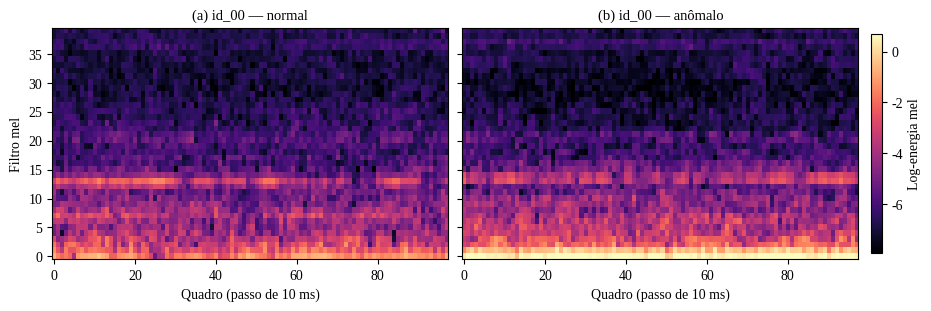

Clipes usados: fan/id_00/normal/00000000.wav e fan/id_00/abnormal/00000000.wav


In [2]:
# 2. Espectrogramas log-mel: as mesmas janelas da conferência visual do notebook 01 (célula 6):
#    1ª janela do 1º clipe normal do inventário e do 1º clipe anômalo da mesma máquina
inv = pd.read_csv(f"{MIMII}/particao_por_gravacao.csv")
g_n = int(np.where(inv.rotulo == 0)[0][0]); MAQUINA = inv.maquina[g_n]
g_a = int(np.where((inv.rotulo == 1) & (inv.maquina == MAQUINA))[0][0])
def janela0(g):
    d = np.load(f"{MIMII}/{inv.particao[g]}.npz")
    return d["X"][np.where((d["grupo"] == g) & (d["janela"] == 0))[0][0]].astype(np.float32)
X = {"n": janela0(g_n), "a": janela0(g_a)}
vmin, vmax = np.percentile(np.concatenate([X["n"], X["a"]]), [1, 99.5])
fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.0), sharey=True, constrained_layout=True)
for a, i, t in [(ax[0], "n", f"(a) {MAQUINA} — normal"), (ax[1], "a", f"(b) {MAQUINA} — anômalo")]:
    im = a.imshow(X[i].T, origin="lower", aspect="auto", cmap="magma", vmin=vmin, vmax=vmax, interpolation="nearest")
    a.set_title(t); a.set_xlabel("Quadro (passo de 10 ms)")
ax[0].set_ylabel("Filtro mel")
cb = fig.colorbar(im, ax=ax, shrink=0.95, pad=0.015); cb.set_label("Log-energia mel")
cb.ax.yaxis.set_major_formatter(virgula)
for ext in ["png", "svg"]: plt.savefig(f"{SAIDA}/Figura_espectrogramas.{ext}")
plt.show()
print("Clipes usados:", inv.membro[g_n], "e", inv.membro[g_a])

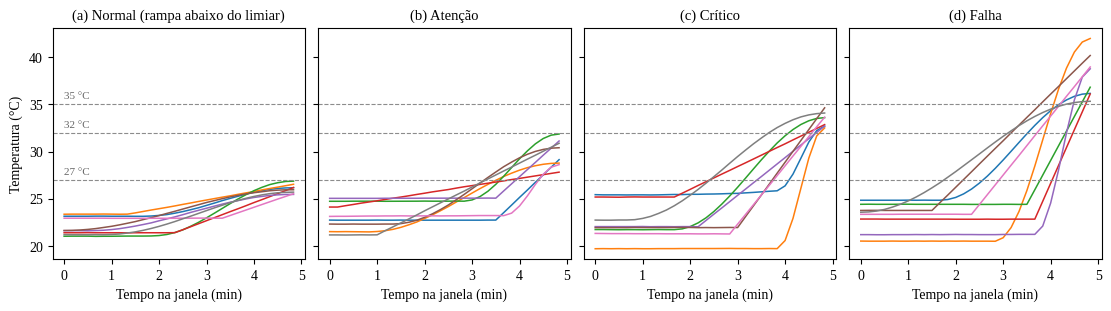

Janelas sintéticas no treino por classe: [23588, 23588, 23588, 23588]


In [3]:
# 3. Rampas sintéticas do Bristol por classe: as mesmas 8 janelas por classe da conferência visual
#    do notebook 02 (célula 7), isto é, as 8 primeiras janelas sintéticas de cada classe no treino
par = json.load(open(f"{BRISTOL}/params_bristol.json"))
LIM, PASSO = par["limites_termicos"], par["passo_s"]
b = np.load(f"{BRISTOL}/treino.npz")
if "sintetica" not in b.files:
    raise SystemExit("treino.npz sem a marcação de janelas sintéticas")
sint = b["sintetica"] == 1
NOMES = ["Normal (rampa abaixo do limiar)", "Atenção", "Crítico", "Falha"]
N_POR_CLASSE = 8
t_min = np.arange(b["X_bruto"].shape[1]) * PASSO / 60
fig, ax = plt.subplots(1, 4, figsize=(11, 3.0), sharey=True, constrained_layout=True)
for c in range(4):
    idx = np.where(sint & (b["y"] == c))[0]
    for i in idx[:N_POR_CLASSE]:
        ax[c].plot(t_min, b["X_bruto"][i, :, 0], lw=1.1)
    for L in LIM:
        ax[c].axhline(L, color="0.55", lw=0.8, ls="--")
    ax[c].set_title(f"({'abcd'[c]}) {NOMES[c]}"); ax[c].set_xlabel("Tempo na janela (min)")
    ax[c].xaxis.set_major_formatter(virgula)
ax[0].set_ylabel("Temperatura (°C)"); ax[0].yaxis.set_major_formatter(virgula)
for L in LIM:
    ax[0].text(t_min[0], L + 0.4, f"{L:g} °C".replace(".", ","), va="bottom", fontsize=8, color="0.4")
for ext in ["png", "svg"]: plt.savefig(f"{SAIDA}/Figura_rampas_sinteticas.{ext}")
plt.show()
print("Janelas sintéticas no treino por classe:", [int((sint & (b['y'] == c)).sum()) for c in range(4)])

## Resultado

Em `dissertacao_tinyml/figuras/`: `Figura_espectrogramas.png/.svg` e `Figura_rampas_sinteticas.png/.svg`, para a seção 3.3.1.